In [3]:

import pandas as pd
import matplotlib.pyplot as plt
import sqlalchemy
import psycopg

print("Все библиотеки работают!")
print("Версия Pandas:", pd.__version__)


Все библиотеки работают!
Версия Pandas: 2.3.3


In [4]:

print("Hello World!")


Hello World!


In [1]:

from sqlalchemy import create_engine, text
from getpass import getpass
from urllib.parse import quote_plus

password = getpass("Введите пароль PostgreSQL: ")

engine = create_engine(
    "postgresql+psycopg://postgres:"
    f"{quote_plus(password)}@localhost:5432/"
    "ecommerce_analytics"
)

with engine.connect() as connection:
    result = connection.execute(
        text("SELECT COUNT(*) FROM orders")
    )
    print("Количество заказов:", result.scalar())


Количество заказов: 99441


In [5]:
query = """
SELECT
    DATE_TRUNC('month', order_purchase_timestamp)::date AS month,
    COUNT(order_id) AS orders_count
FROM orders
WHERE order_status = 'delivered'
GROUP BY DATE_TRUNC('month', order_purchase_timestamp)
ORDER BY month;
"""

df = pd.read_sql(query, engine)

df["month"] = pd.to_datetime(df["month"])

display(df.head(10))


,month,orders_count
0,2016-09-01,1
1,2016-10-01,265
2,2016-12-01,1
3,2017-01-01,750
4,2017-02-01,1653
5,2017-03-01,2546
6,2017-04-01,2303
7,2017-05-01,3546
8,2017-06-01,3135
9,2017-07-01,3872


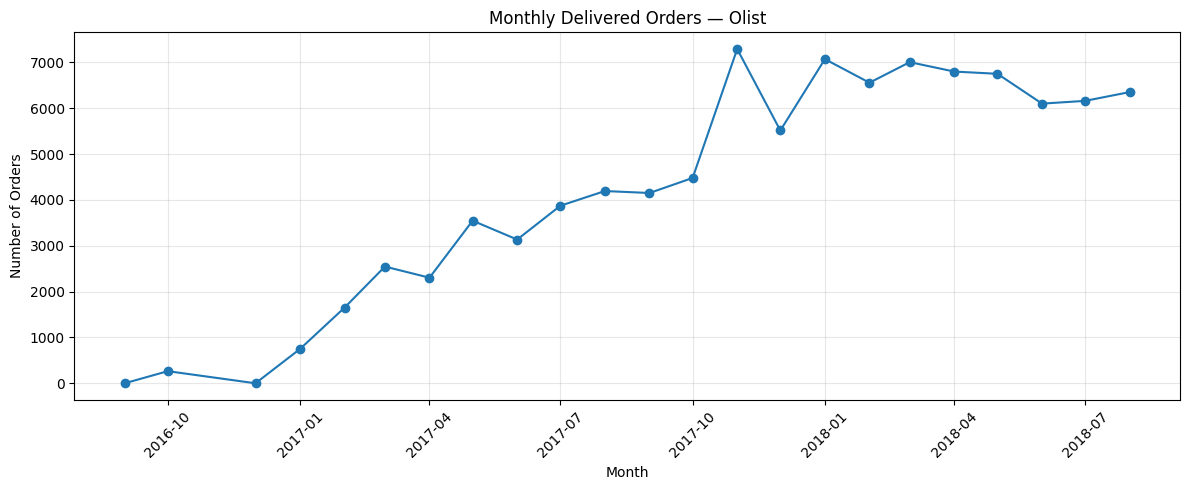

In [44]:
plt.figure(figsize=(12, 5))

plt.plot(
    df["month"],
    df["orders_count"],
    marker="o"
)

plt.title("Monthly Delivered Orders — Olist")
plt.xlabel("Month")
plt.ylabel("Number of Orders")

plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    figures_dir / "monthly_orders.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [14]:

query = """
SELECT
    DATE_TRUNC('month', o.order_purchase_timestamp)::date AS month,
    COUNT(DISTINCT o.order_id) AS orders_count,
    ROUND(SUM(oi.price), 2) AS revenue,
    ROUND(
        SUM(oi.price) / COUNT(DISTINCT o.order_id),
        2
    ) AS aov
FROM orders o
JOIN order_items oi
    ON o.order_id = oi.order_id
WHERE o.order_status = 'delivered'
GROUP BY DATE_TRUNC('month', o.order_purchase_timestamp)
ORDER BY month;
"""

sales_df = pd.read_sql(query, engine)

sales_df["month"] = pd.to_datetime(sales_df["month"])
sales_df["revenue"] = sales_df["revenue"].astype(float)
sales_df["aov"] = sales_df["aov"].astype(float)

display(sales_df.head())


,month,orders_count,revenue,aov
0,2016-09-01,1,134.97,134.97
1,2016-10-01,265,40325.11,152.17
2,2016-12-01,1,10.90,10.90
3,2017-01-01,750,111798.36,149.06
4,2017-02-01,1653,234223.40,141.70


In [41]:

from pathlib import Path

# Находим папку для сохранения графиков
figures_dir = (
    Path("reports/figures")
    if Path("reports").exists()
    else Path("../reports/figures")
)

# Создаём папку, если её нет
figures_dir.mkdir(parents=True, exist_ok=True)

print("Графики сохраняются в:", figures_dir.resolve())


Графики сохраняются в: D:\PetProject\ecommerce-data-analysis\reports\figures


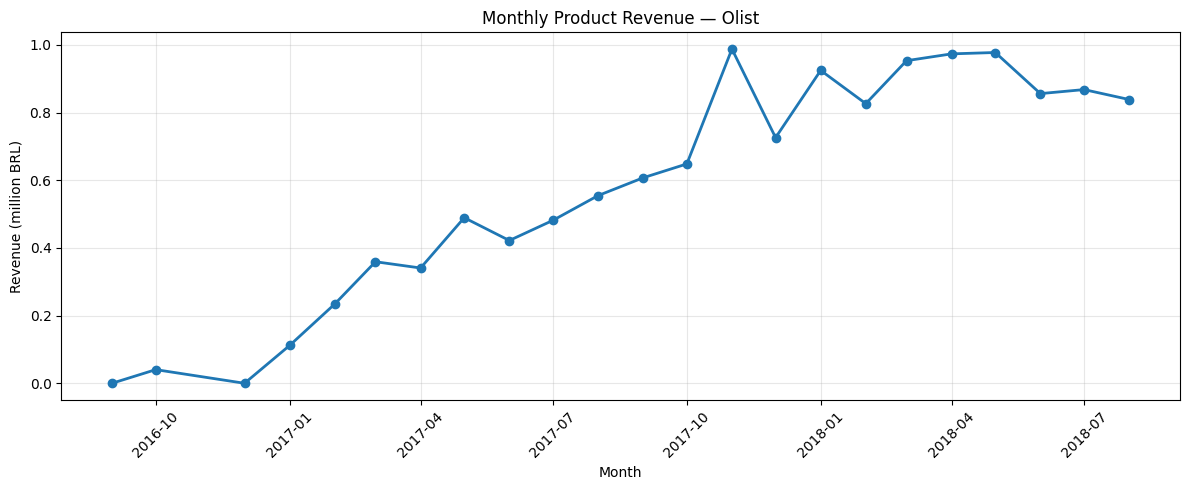

In [42]:

from matplotlib.ticker import FuncFormatter

plt.figure(figsize=(12, 5))

plt.plot(
    sales_df["month"],
    sales_df["revenue"],
    marker="o",
    linewidth=2
)

plt.title("Monthly Product Revenue — Olist")
plt.xlabel("Month")
plt.ylabel("Revenue (million BRL)")

plt.gca().yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"{x / 1_000_000:.1f}")
)

plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()

# Сохраняем график
plt.savefig(
    figures_dir / "monthly_revenue.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


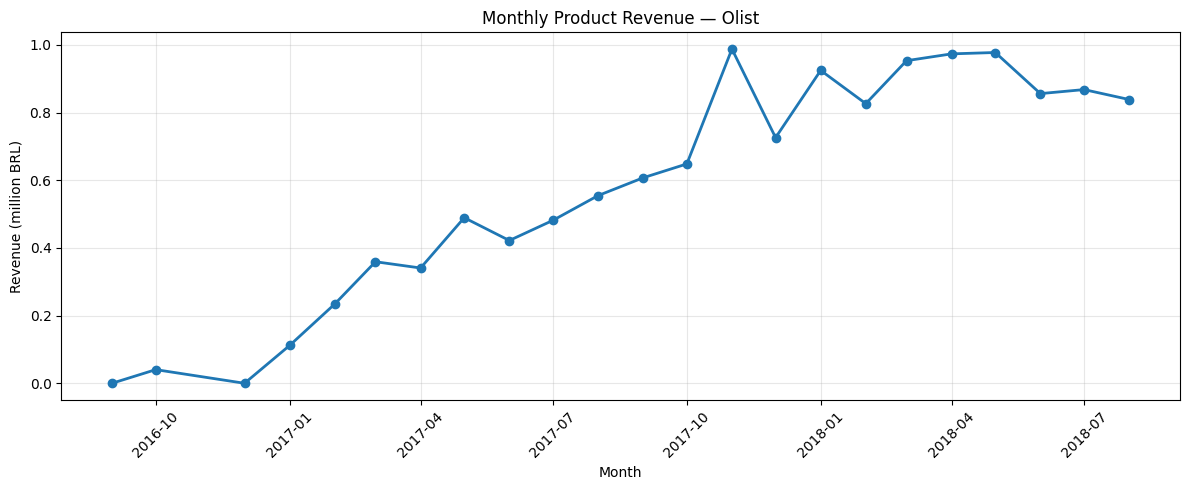

In [ ]:

from matplotlib.ticker import FuncFormatter

plt.figure(figsize=(12, 5))

plt.plot(
    sales_df["month"],
    sales_df["revenue"],
    marker="o",
    linewidth=2
)

plt.title("Monthly Product Revenue — Olist")
plt.xlabel("Month")
plt.ylabel("Revenue (million BRL)")

plt.gca().yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"{x / 1_000_000:.1f}")
)

plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()



plt.show()


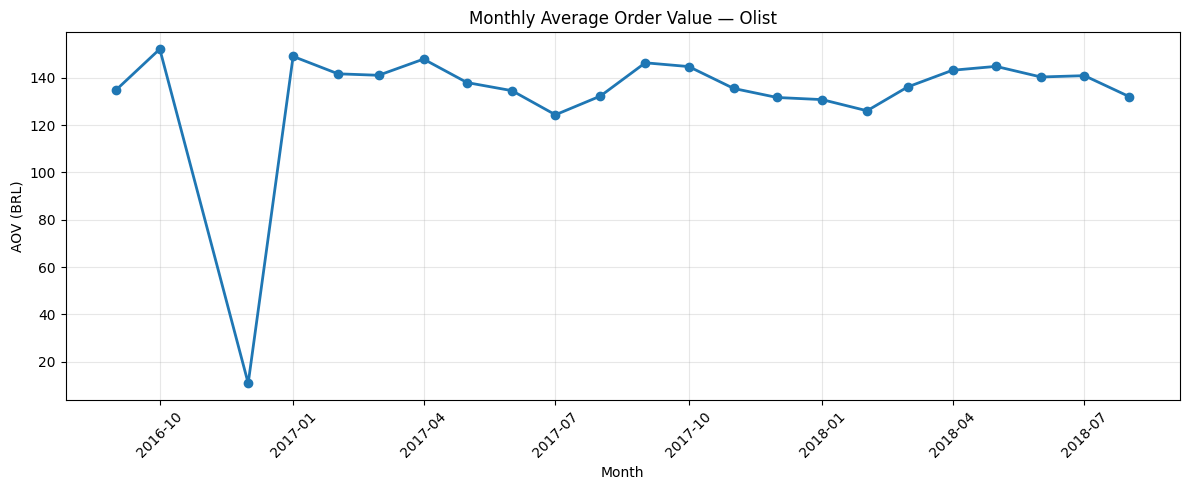

In [43]:
from matplotlib.ticker import FuncFormatter

plt.figure(figsize=(12, 5))

plt.plot(
    sales_df["month"],
    sales_df["aov"],
    marker="o",
    linewidth=2
)

plt.title("Monthly Average Order Value — Olist")
plt.xlabel("Month")
plt.ylabel("AOV (BRL)")



plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(figures_dir / "monthly_aov.png", dpi=300, bbox_inches="tight")

plt.show()

In [20]:
sales_df["orders_growth_pct"] = (
    sales_df["orders_count"].pct_change() * 100
)

In [21]:
display(
    sales_df[
        ["month", "orders_count", "orders_growth_pct"]
    ].head(10)
)

,month,orders_count,orders_growth_pct
0,2016-09-01,1,NaN
1,2016-10-01,265,26400.000000
2,2016-12-01,1,-99.622642
3,2017-01-01,750,74900.000000
4,2017-02-01,1653,120.400000
5,2017-03-01,2546,54.022989
6,2017-04-01,2303,-9.544383
7,2017-05-01,3546,53.973079
8,2017-06-01,3135,-11.590525
9,2017-07-01,3872,23.508772


In [23]:

analysis_df = sales_df[
    (sales_df["month"] >= "2017-01-01") &
    (sales_df["month"] <= "2018-08-01")
].copy()

analysis_df = analysis_df.sort_values("month")

analysis_df["orders_growth_pct"] = (
    analysis_df["orders_count"].pct_change() * 100
)

display(
    analysis_df[
        ["month", "orders_count", "orders_growth_pct"]
    ].head(10)
)


analysis_df["revenue_growth_pct"] = (
    analysis_df["revenue"].pct_change() * 100
)


,month,orders_count,orders_growth_pct
3,2017-01-01,750,NaN
4,2017-02-01,1653,120.400000
5,2017-03-01,2546,54.022989
6,2017-04-01,2303,-9.544383
7,2017-05-01,3546,53.973079
8,2017-06-01,3135,-11.590525
9,2017-07-01,3872,23.508772
10,2017-08-01,4193,8.290289
11,2017-09-01,4150,-1.025519
12,2017-10-01,4478,7.903614


In [24]:

display(
    analysis_df[
        [
            "month",
            "orders_growth_pct",
            "revenue_growth_pct"
        ]
    ].round(2)
)


,month,orders_growth_pct,revenue_growth_pct
3,2017-01-01,NaN,NaN
4,2017-02-01,120.40,109.51
5,2017-03-01,54.02,53.36
6,2017-04-01,-9.54,-5.16
7,2017-05-01,53.97,43.64
8,2017-06-01,-11.59,-13.78
9,2017-07-01,23.51,14.15
10,2017-08-01,8.29,15.18
11,2017-09-01,-1.03,9.50
12,2017-10-01,7.90,6.73


In [25]:

rfm_query = """
SELECT
    c.customer_unique_id,
    MAX(o.order_purchase_timestamp) AS last_purchase_date,
    DATE '2018-09-01' -
        MAX(o.order_purchase_timestamp)::date AS recency_days,
    COUNT(DISTINCT o.order_id) AS orders_count,
    ROUND(SUM(oi.price), 2) AS total_spent
FROM customers c
JOIN orders o
    ON c.customer_id = o.customer_id
JOIN order_items oi
    ON o.order_id = oi.order_id
WHERE o.order_status = 'delivered'
    AND o.order_purchase_timestamp < '2018-09-01'
GROUP BY c.customer_unique_id;
"""

rfm_df = pd.read_sql(rfm_query, engine)

rfm_df["total_spent"] = rfm_df["total_spent"].astype(float)

display(rfm_df.head())
print("Количество покупателей:", len(rfm_df))


,customer_unique_id,last_purchase_date,recency_days,orders_count,total_spent
0,0000366f3b9a7992bf8c76cfdf3221e2,2018-05-10 10:56:27,114,1,129.90
1,0000b849f77a49e4a4ce2b2a4ca5be3f,2018-05-07 11:11:27,117,1,18.90
2,0000f46a3911fa3c0805444483337064,2017-03-10 21:05:03,540,1,69.00
3,0000f6ccb0745a6a4b88665a16c9f078,2017-10-12 20:29:41,324,1,25.99
4,0004aac84e0df4da2b147fca70cf8255,2017-11-14 19:45:42,291,1,180.00


Количество покупателей: 93358


In [26]:

import numpy as np

conditions = [
    (rfm_df["recency_days"] <= 90) &
    (rfm_df["orders_count"] >= 2),

    (rfm_df["recency_days"] <= 90) &
    (rfm_df["orders_count"] == 1),

    rfm_df["recency_days"] > 180
]

labels = [
    "Active Repeat",
    "Recent One-Time",
    "Inactive"
]

rfm_df["segment"] = np.select(
    conditions,
    labels,
    default="Other"
)

display(rfm_df["segment"].value_counts())


segment
Inactive           55799
Other              19486
Recent One-Time    17469
Active Repeat        604
Name: count, dtype: int64

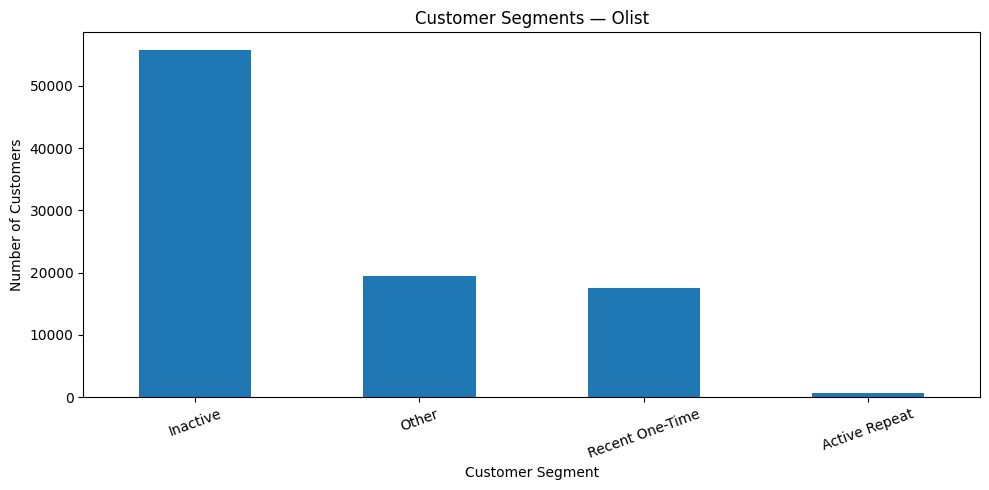

In [45]:
segment_counts = rfm_df["segment"].value_counts()

plt.figure(figsize=(10, 5))

segment_counts.plot(kind="bar")

plt.title("Customer Segments — Olist")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")

plt.xticks(rotation=20)
plt.tight_layout()

plt.savefig(
    figures_dir / "rfm_segments.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [28]:

display(
    rfm_df["total_spent"].describe()
)


count    93358.000000
mean       141.621480
std        215.694014
min          0.850000
25%         47.650000
50%         89.730000
75%        154.737500
max      13440.000000
Name: total_spent, dtype: float64

In [29]:

rfm_df["m_score"] = pd.qcut(
    rfm_df["total_spent"].rank(method="first"),
    q=5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

display(
    rfm_df[
        ["customer_unique_id", "total_spent", "m_score"]
    ].head(10)
)


,customer_unique_id,total_spent,m_score
0,0000366f3b9a7992bf8c76cfdf3221e2,129.90,4
1,0000b849f77a49e4a4ce2b2a4ca5be3f,18.90,1
2,0000f46a3911fa3c0805444483337064,69.00,2
3,0000f6ccb0745a6a4b88665a16c9f078,25.99,1
4,0004aac84e0df4da2b147fca70cf8255,180.00,5
5,0004bd2a26a76fe21f786e4fbd80607f,154.00,4
6,00050ab1314c0e55a6ca13cf7181fecf,27.99,1
7,00053a61a98854899e70ed204dd4bafe,382.00,5
8,0005e1862207bf6ccc02e4228effd9a0,135.00,4
9,0005ef4cd20d2893f0d9fbd94d3c0d97,104.90,3


In [30]:

display(
    rfm_df.groupby("m_score")["total_spent"]
    .agg(["count", "min", "max", "mean"])
    .round(2)
)


,count,min,max,mean
m_score,,,,
1,18672,0.85,39.9,25.59
2,18671,39.90,69.9,53.47
3,18672,69.90,109.9,88.39
4,18671,109.90,179.9,139.72
5,18672,179.90,13440.0,400.93


In [31]:

rfm_df["r_score"] = pd.qcut(
    rfm_df["recency_days"].rank(method="first"),
    q=5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

display(
    rfm_df.groupby("r_score")["recency_days"]
    .agg(["count", "min", "max", "mean"])
    .round(2)
    .sort_index(ascending=False)
)


,count,min,max,mean
r_score,,,,
5,18672,3,95,47.95
4,18671,95,180,137.86
3,18672,180,271,222.37
2,18671,271,385,318.44
1,18672,385,716,475.78


In [32]:

import numpy as np

rfm_df["f_score"] = np.select(
    [
        rfm_df["orders_count"] == 1,
        rfm_df["orders_count"] == 2,
        rfm_df["orders_count"] == 3,
        rfm_df["orders_count"] == 4,
        rfm_df["orders_count"] >= 5
    ],
    [1, 2, 3, 4, 5],
    default=1
)

display(
    rfm_df["f_score"].value_counts().sort_index()
)


f_score
1    90557
2     2573
3      181
4       28
5       19
Name: count, dtype: int64

In [33]:

rfm_df["r_score"] = pd.qcut(
    rfm_df["recency_days"].rank(method="first"),
    q=5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

display(
    rfm_df.groupby("r_score")["recency_days"]
    .agg(["count", "min", "max", "mean"])
    .round(2)
    .sort_index(ascending=False)
)


,count,min,max,mean
r_score,,,,
5,18672,3,95,47.95
4,18671,95,180,137.86
3,18672,180,271,222.37
2,18671,271,385,318.44
1,18672,385,716,475.78


In [34]:

conditions = [
    (rfm_df["r_score"] >= 4) &
    (rfm_df["f_score"] >= 2) &
    (rfm_df["m_score"] >= 4),

    rfm_df["f_score"] >= 2,

    rfm_df["m_score"] == 5,

    rfm_df["r_score"] <= 2
]

labels = [
    "Champions",
    "Loyal Customers",
    "Big Spenders",
    "At Risk"
]

rfm_df["rfm_segment"] = np.select(
    conditions,
    labels,
    default="Regular Customers"
)

display(rfm_df["rfm_segment"].value_counts())


rfm_segment
Regular Customers    44010
At Risk              29293
Big Spenders         17254
Loyal Customers       1868
Champions              933
Name: count, dtype: int64

In [35]:

segment_summary = (
    rfm_df.groupby("rfm_segment")
    .agg(
        customers=("customer_unique_id", "count"),
        avg_recency=("recency_days", "mean"),
        avg_orders=("orders_count", "mean"),
        avg_spent=("total_spent", "mean"),
        total_spent=("total_spent", "sum")
    )
    .round(2)
    .sort_values("total_spent", ascending=False)
)

display(segment_summary)


,customers,avg_recency,avg_orders,avg_spent,total_spent
rfm_segment,,,,,
Big Spenders,17254,243.42,1.00,400.50,6910197.52
Regular Customers,44010,136.21,1.00,76.90,3384422.83
At Risk,29293,397.09,1.00,75.05,2198469.01
Loyal Customers,1868,288.41,2.08,226.36,422841.19
Champions,933,91.46,2.19,327.51,305567.56


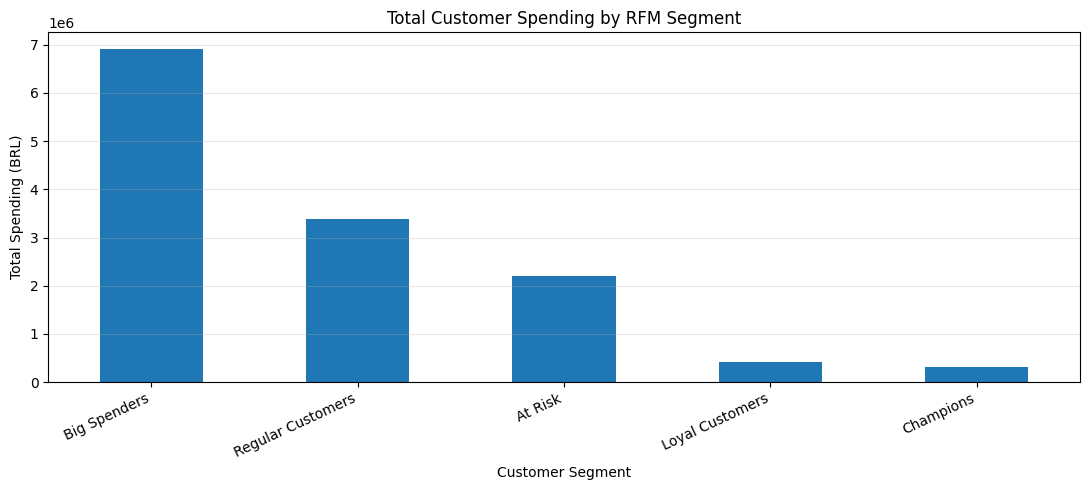

In [36]:

plt.figure(figsize=(11, 5))

segment_summary["total_spent"].plot(kind="bar")

plt.title("Total Customer Spending by RFM Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Spending (BRL)")

plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.show()


In [37]:

segment_summary["revenue_share_pct"] = (
    segment_summary["total_spent"]
    / segment_summary["total_spent"].sum()
    * 100
)

display(
    segment_summary[
        ["customers", "total_spent", "revenue_share_pct"]
    ].round(2)
)


,customers,total_spent,revenue_share_pct
rfm_segment,,,
Big Spenders,17254,6910197.52,52.26
Regular Customers,44010,3384422.83,25.60
At Risk,29293,2198469.01,16.63
Loyal Customers,1868,422841.19,3.20
Champions,933,305567.56,2.31


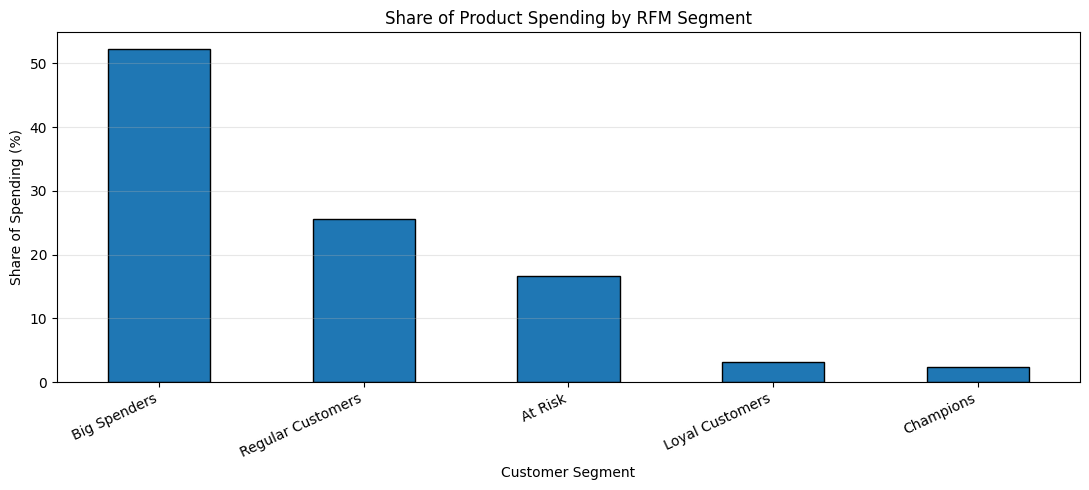

In [46]:

# Рассчитываем долю расходов каждого сегмента
segment_summary["revenue_share_pct"] = (
    segment_summary["total_spent"]
    / segment_summary["total_spent"].sum()
    * 100
)

# Строим график
plt.figure(figsize=(11, 5))

segment_summary["revenue_share_pct"].plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Share of Product Spending by RFM Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Share of Spending (%)")

plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

# Сохраняем график для GitHub
plt.savefig(
    figures_dir / "rfm_spending.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


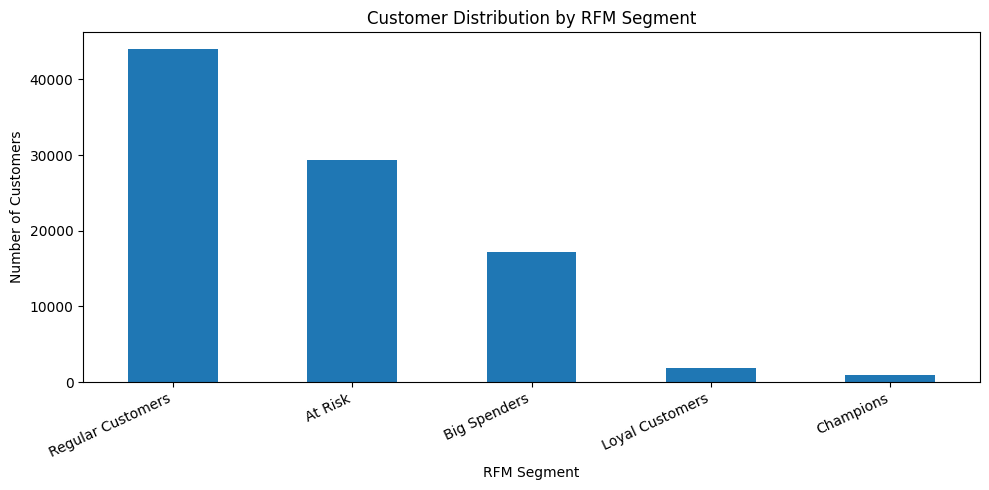

In [47]:

segment_counts = rfm_df["rfm_segment"].value_counts()

plt.figure(figsize=(10, 5))

segment_counts.plot(kind="bar")

plt.title("Customer Distribution by RFM Segment")
plt.xlabel("RFM Segment")
plt.ylabel("Number of Customers")

plt.xticks(rotation=25, ha="right")
plt.tight_layout()

plt.savefig(
    figures_dir / "rfm_segments.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
